# Machine Learning Preprocessing, Clustering, Tuning and Deployment
### A complete hands-on notebook with scikit-learn

**Topics**

1. Missing values and categorical encoding
2. Scaling and normalization
3. Feature selection and domain-informed features
4. `ColumnTransformer` and `Pipeline`
5. K-means clustering and use cases
6. Choosing *k* and interpreting clusters cautiously
7. Hyperparameter tuning with `GridSearchCV` / `RandomizedSearchCV`
8. Cross-validation and reproducibility
9. Feature importance and interpretability caveats
10. Model persistence with `joblib`

**How to use this notebook:** run the cells from top to bottom (*Kernel → Restart & Run All*). Every section has
**concept → code → output → what to notice**, and ends with a short ✍️ **exercise**.

**Running example:** a realistic (synthetic) dataset of **1,000 telecom customers** in Pakistan. The goal is to predict
whether a customer will **churn** (leave). The data has missing values, text categories, skewed numbers and outliers on purpose.

## 0. Setup

In [1]:
import sys, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

SEED = 42                       # one seed, used everywhere → reproducible results
np.random.seed(SEED)
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (7, 4)

print("Python      ", sys.version.split()[0])
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)

Python       3.13.18
numpy        2.5.3
pandas       3.0.5
scikit-learn 1.9.1


### 0.1 Create the dataset
We generate the data with a fixed seed so everyone gets **exactly the same rows**. Churn depends (with noise) on contract type,
tenure, monthly charges, support calls and satisfaction — so a model has something real to learn.

In [2]:
def make_customers(n=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    contract = rng.choice(["Month-to-month", "One year", "Two year"], n, p=[0.55, 0.25, 0.20])
    tenure = np.where(contract == "Month-to-month",
                      rng.integers(1, 36, n), rng.integers(6, 73, n))
    monthly = np.round(rng.gamma(4, 15, n) + 15, 2)               # right-skewed, Rs '00
    df = pd.DataFrame({
        "customer_id": [f"C{i:04d}" for i in range(n)],
        "age": np.clip(rng.normal(38, 12, n), 18, 80).round(),
        "city": rng.choice(["Lahore", "Karachi", "Islamabad", "Faisalabad", "Multan"], n,
                           p=[0.32, 0.30, 0.18, 0.12, 0.08]),
        "contract": contract,
        "payment_method": rng.choice(["Credit card", "Bank transfer", "Cash", "Mobile wallet"], n),
        "tenure_months": tenure,
        "monthly_charges": monthly,
        "total_charges": np.round(tenure * monthly * rng.normal(1, 0.05, n), 2),
        "support_calls": rng.poisson(1.5, n),
        "satisfaction": rng.choice(["Low", "Medium", "High"], n, p=[0.25, 0.45, 0.30]),
    })
    # a few extreme bills (outliers)
    idx = rng.choice(n, 8, replace=False)
    df.loc[idx, "monthly_charges"] *= 4
    # churn probability from a hidden logistic model
    logit = (-1.2
             + 1.4 * (df.contract == "Month-to-month")
             - 0.04 * df.tenure_months
             + 0.012 * df.monthly_charges
             + 0.35 * df.support_calls
             + 0.9 * (df.satisfaction == "Low") - 0.6 * (df.satisfaction == "High"))
    df["churn"] = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)
    # missing values: some at random, total_charges missing for brand-new customers
    for col, frac in [("age", 0.06), ("payment_method", 0.04), ("satisfaction", 0.08)]:
        df.loc[rng.random(n) < frac, col] = np.nan
    df.loc[df.tenure_months <= 2, "total_charges"] = np.nan
    return df

df = make_customers()
print(df.shape)
df.head()

(1000, 11)


,customer_id,age,city,contract,payment_method,tenure_months,monthly_charges,total_charges,support_calls,satisfaction,churn
0,C0000,29.0,Karachi,One year,Credit card,58,45.51,2582.17,4,Medium,0
1,C0001,67.0,Karachi,Month-to-month,Credit card,3,42.18,124.96,2,Low,1
2,C0002,37.0,Karachi,Two year,Bank transfer,68,54.83,3517.82,6,High,0
3,C0003,33.0,Multan,One year,Credit card,70,53.58,3629.01,0,Low,0
4,C0004,38.0,Lahore,Month-to-month,Credit card,28,253.96,1933.99,2,Medium,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   customer_id      1000 non-null   str    
 1   age              949 non-null    float64
 2   city             1000 non-null   str    
 3   contract         1000 non-null   str    
 4   payment_method   965 non-null    str    
 5   tenure_months    1000 non-null   int64  
 6   monthly_charges  1000 non-null   float64
 7   total_charges    970 non-null    float64
 8   support_calls    1000 non-null   int64  
 9   satisfaction     927 non-null    str    
 10  churn            1000 non-null   int64  
dtypes: float64(3), int64(3), str(5)
memory usage: 86.1 KB


In [4]:
print("Churn rate:", round(df.churn.mean(), 3))
df.describe().round(1)

Churn rate: 0.524


,age,tenure_months,monthly_charges,total_charges,support_calls,churn
count,949.0,1000.0,1000.0,970.0,1000.0,1000.0
mean,38.1,27.8,78.6,2205.0,1.5,0.5
std,11.4,18.5,38.5,1716.2,1.2,0.5
min,18.0,1.0,22.0,96.9,0.0,0.0
25%,30.0,13.0,54.0,931.5,1.0,0.0
50%,38.0,24.0,72.7,1723.5,1.0,1.0
75%,45.0,36.2,93.3,3042.6,2.0,1.0
max,79.0,72.0,438.7,10055.8,8.0,1.0


---
## 1. Missing values and categorical encoding

### 1.1 Find and understand the missing values
Before fixing missing values, ask **why** they are missing:

| Type | Meaning | Example here |
|---|---|---|
| **MCAR** – completely at random | nothing explains it | `age` left blank by chance |
| **MAR** – at random given other columns | depends on observed data | — |
| **MNAR** – not at random | depends on the missing value itself / a real situation | `total_charges` is empty because the customer is **new** (tenure ≤ 2) |

MNAR missingness often **carries information** — keep it with a missing-indicator column.

In [5]:
missing = (df.isna().sum()
             .to_frame("n_missing")
             .assign(pct=lambda t: (100 * t.n_missing / len(df)).round(1))
             .query("n_missing > 0"))
missing

,n_missing,pct
age,51,5.1
payment_method,35,3.5
total_charges,30,3.0
satisfaction,73,7.3


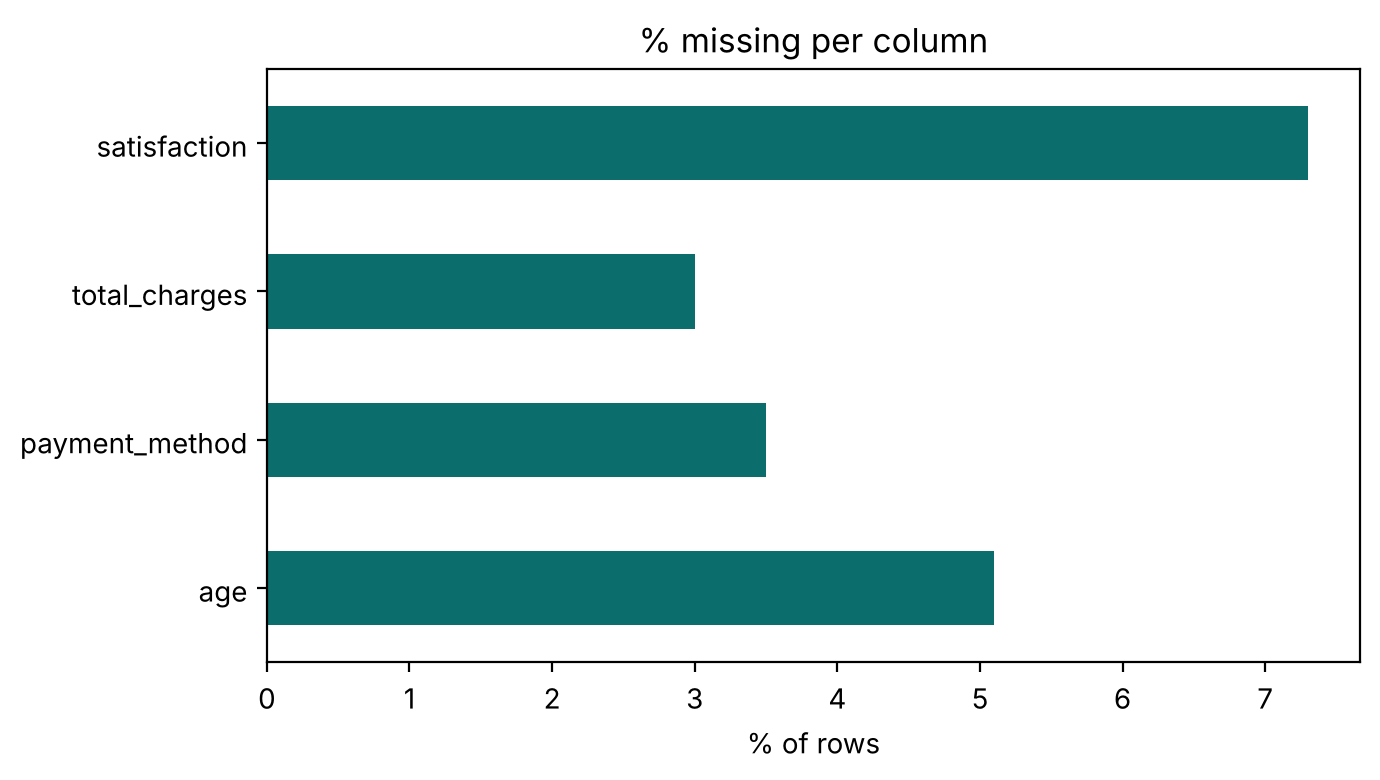

               min  max  count
total_charges                 
False            3   72    970
True             1    2     30


In [6]:
missing.pct.plot.barh(color="#0B6E6D", title="% missing per column")
plt.xlabel("% of rows"); plt.tight_layout(); plt.show()

# Is total_charges missing at random? No — it is missing only for new customers:
print(df.groupby(df.total_charges.isna()).tenure_months.agg(["min", "max", "count"]))

### 1.2 Strategies for missing values

| Strategy | When to use | Risk |
|---|---|---|
| Drop rows (`dropna`) | very few rows missing, MCAR | lose data, bias if not MCAR |
| Drop column | column mostly empty and unimportant | lose signal |
| Mean | numeric, roughly symmetric | pulled by outliers |
| **Median** | numeric, skewed or with outliers | — |
| Most frequent / constant `"Missing"` | categorical | — |
| + **missing indicator** | when missingness itself is informative (MNAR) | extra columns |
| KNN / Iterative imputer | many related features | slower, can leak if fit on all data |

**Golden rule:** compute imputation values on the **training data only**, then apply them to test data. A `Pipeline` does this automatically (Section 4).

In [7]:
from sklearn.impute import SimpleImputer

# Mean vs median on a skewed column with outliers
col = df[["monthly_charges"]]
print("mean   :", round(col.monthly_charges.mean(), 2))
print("median :", round(col.monthly_charges.median(), 2))

# Impute total_charges with the median AND add an indicator column
imp = SimpleImputer(strategy="median", add_indicator=True)
out = imp.fit_transform(df[["total_charges"]])
print("\nlearned median:", imp.statistics_)
print("output columns:", imp.get_feature_names_out())
pd.DataFrame(out, columns=imp.get_feature_names_out())[df.total_charges.isna().values].head()

mean   : 78.56
median : 72.66

learned median: [1723.52]
output columns: ['total_charges' 'missingindicator_total_charges']


,total_charges,missingindicator_total_charges
37,1723.52,1.0
89,1723.52,1.0
137,1723.52,1.0
170,1723.52,1.0
202,1723.52,1.0


In [8]:
# Categorical imputation: most frequent vs an explicit "Missing" category
cat_imp_mode = SimpleImputer(strategy="most_frequent")
cat_imp_const = SimpleImputer(strategy="constant", fill_value="Missing")
sample = df[["payment_method"]].iloc[:12]
pd.DataFrame({
    "original": sample.payment_method,
    "most_frequent": cat_imp_mode.fit(df[["payment_method"]]).transform(sample).ravel(),
    "constant": cat_imp_const.fit(df[["payment_method"]]).transform(sample).ravel(),
})[sample.payment_method.isna().values | (np.arange(12) < 3)]

,original,most_frequent,constant
0,Credit card,Credit card,Credit card
1,Credit card,Credit card,Credit card
2,Bank transfer,Bank transfer,Bank transfer
8,NaN,Credit card,Missing


### 1.3 Encoding categorical features
Models need numbers. How you convert text depends on the **type** of category:

* **Nominal** (no order): `city`, `payment_method`, `contract` → **One-hot encoding**
* **Ordinal** (natural order): `satisfaction` = Low < Medium < High → **Ordinal encoding with an explicit order**

⚠️ Never give nominal categories numbers like Lahore=0, Karachi=1, Islamabad=2 for a linear model — it invents an order that doesn't exist.

In [9]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
city_ohe = ohe.fit_transform(df[["city"]])
print(ohe.get_feature_names_out())
pd.DataFrame(city_ohe, columns=ohe.get_feature_names_out()).head(4).astype(int).assign(city=df.city.head(4))

['city_Faisalabad' 'city_Islamabad' 'city_Karachi' 'city_Lahore'
 'city_Multan']


,city_Faisalabad,city_Islamabad,city_Karachi,city_Lahore,city_Multan,city
0,0,0,1,0,0,Karachi
1,0,0,1,0,0,Karachi
2,0,0,1,0,0,Karachi
3,0,0,0,0,1,Multan


In [10]:
ord_enc = OrdinalEncoder(categories=[["Low", "Medium", "High"]],
                         handle_unknown="use_encoded_value", unknown_value=-1)
sat = df[["satisfaction"]].fillna("Medium")          # (imputation first — later done in a pipeline)
pd.DataFrame({"satisfaction": sat.satisfaction.head(6),
              "encoded": ord_enc.fit_transform(sat).ravel()[:6]})

,satisfaction,encoded
0,Medium,1.0
1,Low,0.0
2,High,2.0
3,Low,0.0
4,Medium,1.0
5,High,2.0


### 1.4 Why `pd.get_dummies` is risky in ML
`get_dummies` creates columns from whatever categories appear **in that DataFrame**. If the test data (or tomorrow's data) has a
new or missing category, the columns don't match. `OneHotEncoder` remembers the training categories.

In [11]:
train_part = pd.DataFrame({"city": ["Lahore", "Karachi", "Lahore"]})
new_data   = pd.DataFrame({"city": ["Quetta", "Karachi"]})       # Quetta never seen before

print("get_dummies train cols:", list(pd.get_dummies(train_part).columns))
print("get_dummies new cols  :", list(pd.get_dummies(new_data).columns), " ← different!")

enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(train_part)
print("\nOneHotEncoder on new data (same columns, Quetta → all zeros):")
print(pd.DataFrame(enc.transform(new_data), columns=enc.get_feature_names_out(), index=new_data.city))

get_dummies train cols: ['city_Karachi', 'city_Lahore']
get_dummies new cols  : ['city_Karachi', 'city_Quetta']  ← different!

OneHotEncoder on new data (same columns, Quetta → all zeros):
         city_Karachi  city_Lahore
city                              
Quetta            0.0          0.0
Karachi           1.0          0.0


> ✍️ **Exercise 1:** Impute `age` with the median and add an indicator. Then one-hot encode `contract` with `drop="first"`.
> How many columns do you get, and why might `drop="first"` matter for linear regression but not for a random forest?

---
## 2. Scaling and normalization

Features live on very different scales: `age` ≈ 18–80, `total_charges` ≈ 0–9,000. Distance-based and gradient-based models
let the large-number feature dominate.

| Transformer | Formula | Use when |
|---|---|---|
| `StandardScaler` | (x − mean) / std | default for linear models, SVM, KNN, k-means, PCA |
| `MinMaxScaler` | (x − min) / (max − min) → [0, 1] | bounded inputs, neural nets, images |
| `RobustScaler` | (x − median) / IQR | **outliers** present |
| `Normalizer` | each **row** scaled to length 1 | text vectors, cosine similarity (different idea!) |
| `np.log1p` / `PowerTransformer` | reshape skewed distributions | long right tails (money, counts) |

**Trees and forests do not need scaling** — they split on thresholds, which don't care about units.

In [12]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, Normalizer

x = df[["monthly_charges"]]
scaled = pd.DataFrame({
    "raw": x.monthly_charges,
    "standard": StandardScaler().fit_transform(x).ravel(),
    "minmax": MinMaxScaler().fit_transform(x).ravel(),
    "robust": RobustScaler().fit_transform(x).ravel(),
})
scaled.describe().loc[["mean", "std", "min", "50%", "max"]].round(2)

,raw,standard,minmax,robust
mean,78.56,-0.00,0.14,0.15
std,38.54,1.00,0.09,0.98
min,21.95,-1.47,0.00,-1.29
50%,72.66,-0.15,0.12,0.00
max,438.72,9.35,1.00,9.32


**What to notice:** the 8 extreme bills squeeze `MinMaxScaler` — most customers end up crammed near 0 because the max is huge.
`RobustScaler` uses the median and IQR, so ordinary customers keep a sensible spread.

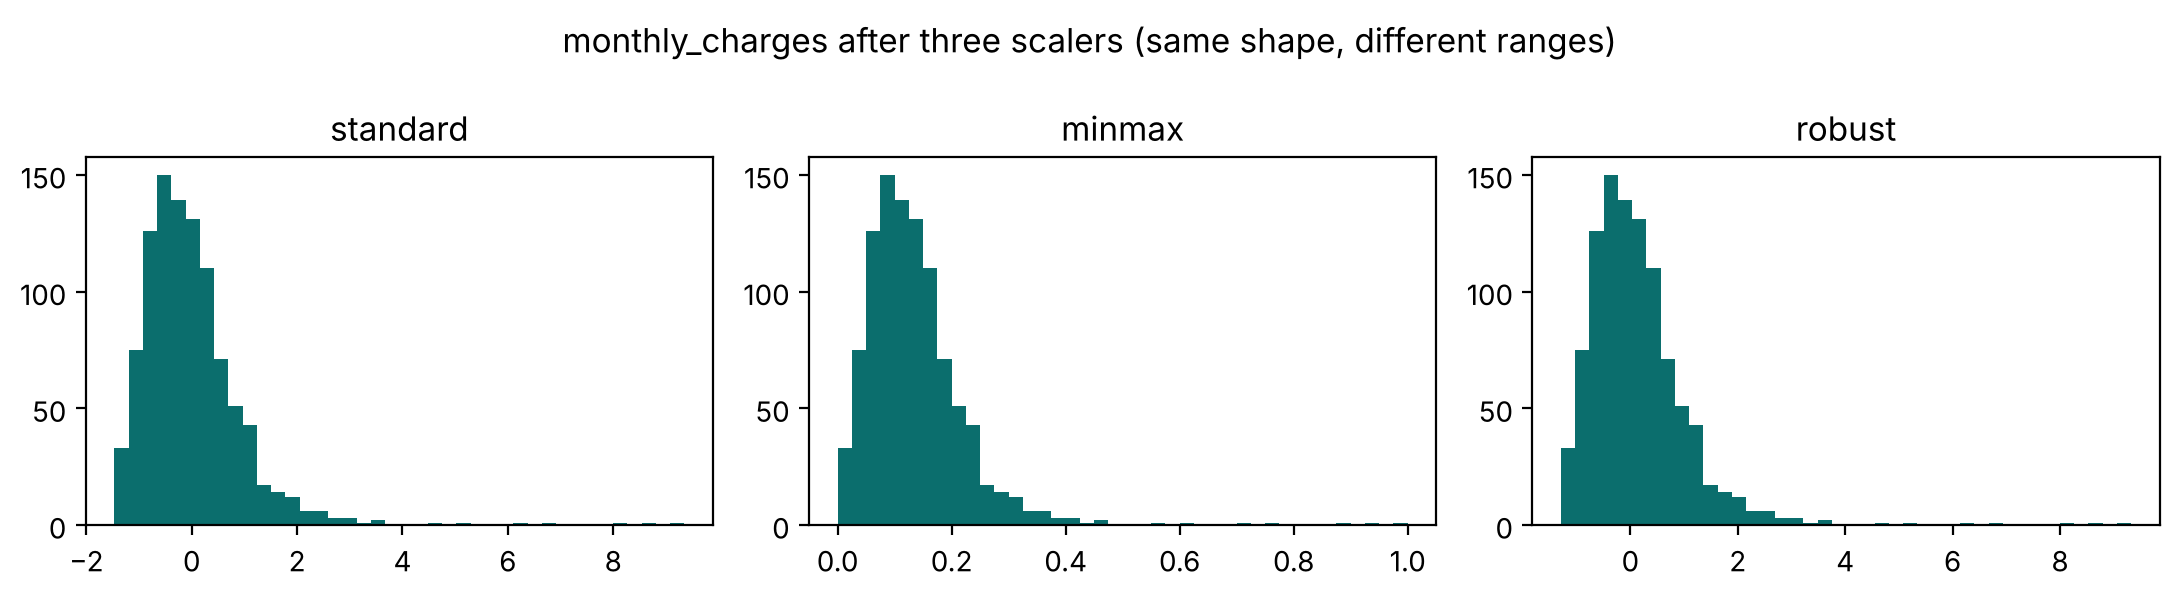

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, c in zip(axes, ["standard", "minmax", "robust"]):
    ax.hist(scaled[c], bins=40, color="#0B6E6D"); ax.set_title(c)
plt.suptitle("monthly_charges after three scalers (same shape, different ranges)")
plt.tight_layout(); plt.show()

In [14]:
# Log transform for skew
print("skew before:", round(df.monthly_charges.skew(), 2),
      "| skew after log1p:", round(np.log1p(df.monthly_charges).skew(), 2))

# Normalizer works on ROWS, not columns: every row gets length 1
rows = np.array([[3.0, 4.0], [30.0, 40.0]])
print("\nNormalizer rows:\n", Normalizer().fit_transform(rows), " ← both rows become identical")

skew before: 3.23 | skew after log1p: 0.24

Normalizer rows:
 [[0.6 0.8]
 [0.6 0.8]]  ← both rows become identical


### 2.1 Proof that scaling matters: KNN with and without scaling

In [15]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline

Xbc, ybc = load_breast_cancer(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(Xbc, ybc, test_size=0.25, stratify=ybc, random_state=SEED)

results = {
    "KNN, raw":            KNeighborsClassifier().fit(Xtr, ytr).score(Xte, yte),
    "KNN, scaled":         make_pipeline(StandardScaler(), KNeighborsClassifier()).fit(Xtr, ytr).score(Xte, yte),
    "Tree, raw":           DecisionTreeClassifier(random_state=SEED).fit(Xtr, ytr).score(Xte, yte),
    "Tree, scaled":        make_pipeline(StandardScaler(), DecisionTreeClassifier(random_state=SEED)).fit(Xtr, ytr).score(Xte, yte),
}
pd.Series(results, name="test accuracy").round(3)

KNN, raw        0.930
KNN, scaled     0.979
Tree, raw       0.923
Tree, scaled    0.923
Name: test accuracy, dtype: float64

**What to notice:** scaling helps KNN noticeably because it measures distances, while the decision tree gives the same accuracy
either way.

> ✍️ **Exercise 2:** Repeat the KNN experiment with `MinMaxScaler` and `RobustScaler`. Which works best here, and why might
> the answer change on a dataset with strong outliers?

---
## 3. Feature selection and domain-informed features

### 3.1 Domain-informed features
The best features often come from **knowing the business**, not from algorithms. Telecom experts would say:

* `avg_charge` = total_charges / tenure — what the customer *really* pays per month
* `is_new_customer` = tenure ≤ 6 months — new customers churn more
* `calls_per_year` = support_calls / years of tenure — frequent complainers are at risk
* `long_contract` = contract is One or Two year

We write them as a **function**, so the exact same logic runs on training data, test data and live data.

In [16]:
def add_domain_features(X: pd.DataFrame) -> pd.DataFrame:
    X = X.copy()
    tenure = X["tenure_months"].clip(lower=1)
    X["avg_charge"] = X["total_charges"] / tenure
    X["is_new_customer"] = (X["tenure_months"] <= 6).astype(int)
    X["calls_per_year"] = X["support_calls"] / (tenure / 12)
    X["long_contract"] = X["contract"].isin(["One year", "Two year"]).astype(int)
    return X

fe = add_domain_features(df)
fe.groupby("is_new_customer").churn.mean().rename("churn rate").to_frame()

,churn rate
is_new_customer,
0,0.486577
1,0.839623


In [17]:
# Quick check: do the new features relate to churn?
fe[["tenure_months", "monthly_charges", "avg_charge", "calls_per_year",
    "is_new_customer", "long_contract", "support_calls", "churn"]].corr()["churn"].drop("churn").sort_values().round(3)

tenure_months     -0.453
long_contract     -0.452
avg_charge         0.122
support_calls      0.126
monthly_charges    0.129
is_new_customer    0.218
calls_per_year     0.220
Name: churn, dtype: float64

### 3.2 Feature selection methods

| Family | Examples | Idea |
|---|---|---|
| **Filter** | `VarianceThreshold`, correlation, `SelectKBest(mutual_info_classif)` | score each feature alone, fast |
| **Wrapper** | `RFE`, `SequentialFeatureSelector` | try subsets with a model, slower |
| **Embedded** | L1 (Lasso) logistic regression, tree importances via `SelectFromModel` | selection happens during training |

Why select? fewer features → simpler, faster models, less overfitting, easier to explain.
⚠️ Selection must be **learned on training data only** (inside a pipeline), otherwise it leaks — proven in Section 8.

In [18]:
from sklearn.feature_selection import VarianceThreshold, SelectKBest, mutual_info_classif, RFE
from sklearn.linear_model import LogisticRegression

num_cols = ["age", "tenure_months", "monthly_charges", "total_charges", "support_calls",
            "avg_charge", "calls_per_year", "is_new_customer", "long_contract"]
Xn = fe[num_cols].fillna(fe[num_cols].median())
Xn = Xn.assign(constant_col=1.0)                       # a useless column on purpose
Xn_s = pd.DataFrame(StandardScaler().fit_transform(Xn), columns=Xn.columns)

# Filter 1: drop features with (almost) no variance
vt = VarianceThreshold(threshold=0.0).fit(Xn)
print("VarianceThreshold drops:", list(Xn.columns[~vt.get_support()]))

# Filter 2: mutual information with the target
mi = SelectKBest(mutual_info_classif, k=5).fit(Xn, fe.churn)
print("\nMutual information scores:")
print(pd.Series(mi.scores_, index=Xn.columns).sort_values(ascending=False).round(3))

VarianceThreshold drops: ['constant_col']



Mutual information scores:
long_contract      0.117
tenure_months      0.101
calls_per_year     0.092
total_charges      0.069
monthly_charges    0.034
avg_charge         0.029
is_new_customer    0.015
age                0.000
support_calls      0.000
constant_col       0.000
dtype: float64


In [19]:
# Wrapper: Recursive Feature Elimination with logistic regression
rfe = RFE(LogisticRegression(max_iter=1000), n_features_to_select=5).fit(Xn_s, fe.churn)
print("RFE keeps:", list(Xn.columns[rfe.support_]))

# Embedded: L1 penalty pushes weak coefficients to exactly 0
l1 = LogisticRegression(l1_ratio=1.0, solver="saga", C=0.05, max_iter=5000).fit(Xn_s, fe.churn)
pd.Series(l1.coef_[0], index=Xn.columns).round(3).sort_values()

RFE keeps: ['tenure_months', 'monthly_charges', 'support_calls', 'calls_per_year', 'long_contract']


tenure_months     -0.662
long_contract     -0.556
total_charges      0.000
age                0.000
is_new_customer    0.000
avg_charge         0.000
constant_col       0.000
calls_per_year     0.030
support_calls      0.237
monthly_charges    0.240
dtype: float64

**What to notice:** every method puts **tenure** and **contract length** near the top, but they disagree elsewhere — mutual
information scores `support_calls` as 0, while RFE and L1 both keep it (it matters *together with* the other features).
Selection is evidence, not truth. Correlated features (`tenure_months`, `total_charges`, `long_contract`) also compete: L1 keeps
one and zeroes `total_charges`.

> ✍️ **Exercise 3:** Invent one more domain feature (for example `charges_per_call`). Does it rank in the top 5 by mutual information?

---
## 4. `ColumnTransformer` and `Pipeline`

Real tables mix types; each needs different preprocessing. `ColumnTransformer` sends each group of columns to its own steps,
and `Pipeline` chains everything with the model into **one object** with `.fit()` and `.predict()`.

```
                    ┌─ numeric  : impute median (+indicator) → scale ─┐
raw DataFrame → FE ─┼─ nominal  : impute "Missing" → one-hot          ├→ model
                    └─ ordinal  : impute "Medium" → ordinal encode  ──┘
```

Benefits: no leakage (fit only on train folds), less code, same steps at predict time, saved as one file.

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

target = "churn"
X = df.drop(columns=[target, "customer_id"])          # IDs carry no general signal
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print("train:", X_train.shape, " test:", X_test.shape, " churn rate train/test:",
      round(y_train.mean(), 3), round(y_test.mean(), 3))

train: (800, 9)  test: (200, 9)  churn rate train/test: 0.524 0.525


In [21]:
numeric = ["age", "tenure_months", "monthly_charges", "total_charges", "support_calls",
           "avg_charge", "calls_per_year", "is_new_customer", "long_contract"]
nominal = ["city", "contract", "payment_method"]
ordinal = ["satisfaction"]

num_pipe = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                     ("scale", StandardScaler())])
nom_pipe = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
ord_pipe = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Medium")),
                     ("ordinal", OrdinalEncoder(categories=[["Low", "Medium", "High"]]))])

preprocess = ColumnTransformer([
    ("num", num_pipe, numeric),
    ("nom", nom_pipe, nominal),
    ("ord", ord_pipe, ordinal),
], remainder="drop")

model = Pipeline([
    ("features", FunctionTransformer(add_domain_features)),   # domain features, inside the pipeline
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=1000)),
])
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...x7f5a121feca0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictionary 

In [22]:
model.fit(X_train, y_train)
print("Test accuracy:", round(model.score(X_test, y_test), 3))

names = model.named_steps["prep"].get_feature_names_out()
print(len(names), "features after preprocessing:")
print(list(names))

Test accuracy: 0.705
26 features after preprocessing:
['num__age', 'num__tenure_months', 'num__monthly_charges', 'num__total_charges', 'num__support_calls', 'num__avg_charge', 'num__calls_per_year', 'num__is_new_customer', 'num__long_contract', 'num__missingindicator_age', 'num__missingindicator_total_charges', 'num__missingindicator_avg_charge', 'nom__city_Faisalabad', 'nom__city_Islamabad', 'nom__city_Karachi', 'nom__city_Lahore', 'nom__city_Multan', 'nom__contract_Month-to-month', 'nom__contract_One year', 'nom__contract_Two year', 'nom__payment_method_Bank transfer', 'nom__payment_method_Cash', 'nom__payment_method_Credit card', 'nom__payment_method_Missing', 'nom__payment_method_Mobile wallet', 'ord__satisfaction']


In [23]:
# Look inside: the transformed training data as a DataFrame
from sklearn.base import clone
prep_only = clone(Pipeline(model.steps[:-1])).set_output(transform="pandas")   # clone: don't change `model`
prep_only.fit_transform(X_train).head(3).round(2)

,num__age,num__tenure_months,num__monthly_charges,num__total_charges,num__support_calls,num__avg_charge,num__calls_per_year,num__is_new_customer,num__long_contract,num__missingindicator_age,...,nom__city_Multan,nom__contract_Month-to-month,nom__contract_One year,nom__contract_Two year,nom__payment_method_Bank transfer,nom__payment_method_Cash,nom__payment_method_Credit card,nom__payment_method_Missing,nom__payment_method_Mobile wallet,ord__satisfaction
327,-0.28,-1.16,-0.97,-1.16,0.38,-1.27,0.80,2.79,-0.88,-0.24,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,2.0
802,0.55,1.70,0.64,2.27,-0.44,0.78,-0.41,-0.36,1.14,-0.24,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0
206,0.36,-1.22,-0.87,-1.16,0.38,-1.06,1.05,2.79,-0.88,-0.24,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0


In [24]:
# Predict on brand-new raw rows — missing values and an unseen city included
new_customers = pd.DataFrame([
    {"age": np.nan, "city": "Quetta", "contract": "Month-to-month", "payment_method": np.nan,
     "tenure_months": 2, "monthly_charges": 95.0, "total_charges": np.nan, "support_calls": 4, "satisfaction": "Low"},
    {"age": 45, "city": "Lahore", "contract": "Two year", "payment_method": "Bank transfer",
     "tenure_months": 60, "monthly_charges": 55.0, "total_charges": 3300.0, "support_calls": 0, "satisfaction": "High"},
])
pd.DataFrame({"churn_probability": model.predict_proba(new_customers)[:, 1].round(3),
              "prediction": model.predict(new_customers)})

,churn_probability,prediction
0,0.993,1
1,0.036,0


**What to notice:** the pipeline handled raw input end-to-end — missing values, an unseen city, domain features, scaling and
encoding — with one `.predict_proba()` call.

> ✍️ **Exercise 4:** Swap `LogisticRegression` for `RandomForestClassifier(random_state=SEED)` by changing only the last step.
> Which steps could you remove for a forest, and does accuracy change?

---
## 5. K-means clustering and use cases

K-means splits rows into *k* groups by repeating two steps until nothing changes:

1. **Assign** each point to the nearest centroid
2. **Update** each centroid to the mean of its points

It minimises the within-cluster sum of squares (**inertia**). It assumes roughly round, similar-sized clusters and **needs scaled
features**.

**Typical use cases:** customer segmentation · grouping products or stores · compressing colours in images ·
creating a “segment” feature for a supervised model · first look at unlabeled data.

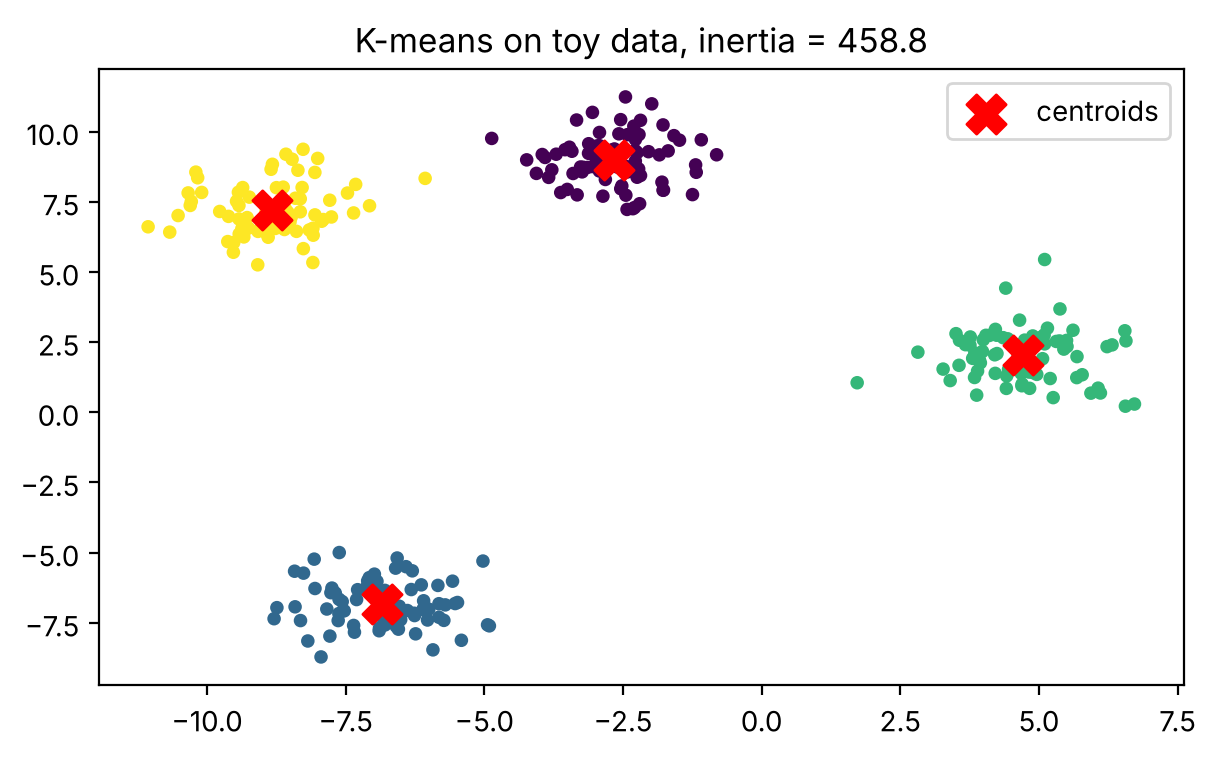

In [25]:
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

Xb, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.9, random_state=SEED)
km = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(Xb)

plt.scatter(Xb[:, 0], Xb[:, 1], c=km.labels_, cmap="viridis", s=15)
plt.scatter(*km.cluster_centers_.T, c="red", marker="X", s=200, label="centroids")
plt.legend(); plt.title(f"K-means on toy data, inertia = {km.inertia_:.1f}"); plt.show()

### 5.1 Use case: segmenting our customers (no churn label used)

In [26]:
seg_cols = ["tenure_months", "monthly_charges", "support_calls"]
seg_raw = df[seg_cols]
seg_pipe = make_pipeline(StandardScaler(), KMeans(n_clusters=4, n_init=10, random_state=SEED))
df["segment"] = seg_pipe.fit_predict(seg_raw)

profile = (df.groupby("segment")
             .agg(customers=("segment", "size"),
                  tenure=("tenure_months", "mean"),
                  monthly=("monthly_charges", "mean"),
                  calls=("support_calls", "mean"),
                  churn_rate=("churn", "mean"))
             .round(2))
profile

,customers,tenure,monthly,calls,churn_rate
segment,,,,,
0,368,18.61,69.68,0.58,0.57
1,209,56.66,72.85,1.33,0.13
2,88,24.16,161.39,1.48,0.69
3,335,20.79,70.10,2.72,0.68


**Reading the profile:** we describe each segment with **averages of the original, unscaled columns**. Churn was *not* used to build
the clusters — looking at it afterwards shows whether the segments are useful for the business.

Possible reading (check against the table above): one segment of **long-tenure, loyal** customers with low churn; one with
**very high bills**; one with **many support calls**; and one of **newer, quieter** customers. The high-bill and many-calls
segments churn most — candidates for a retention offer or a support follow-up.

---
## 6. Choosing *k* and interpreting clusters cautiously

There is no single “correct” *k*. Use several pieces of evidence:

* **Elbow:** inertia always falls as *k* rises; look for the bend
* **Silhouette score** (−1 to 1): how much closer points are to their own cluster than the next one
* **Stability:** do clusters stay the same across random seeds / subsamples?
* **Usefulness:** can a person describe and act on each segment?

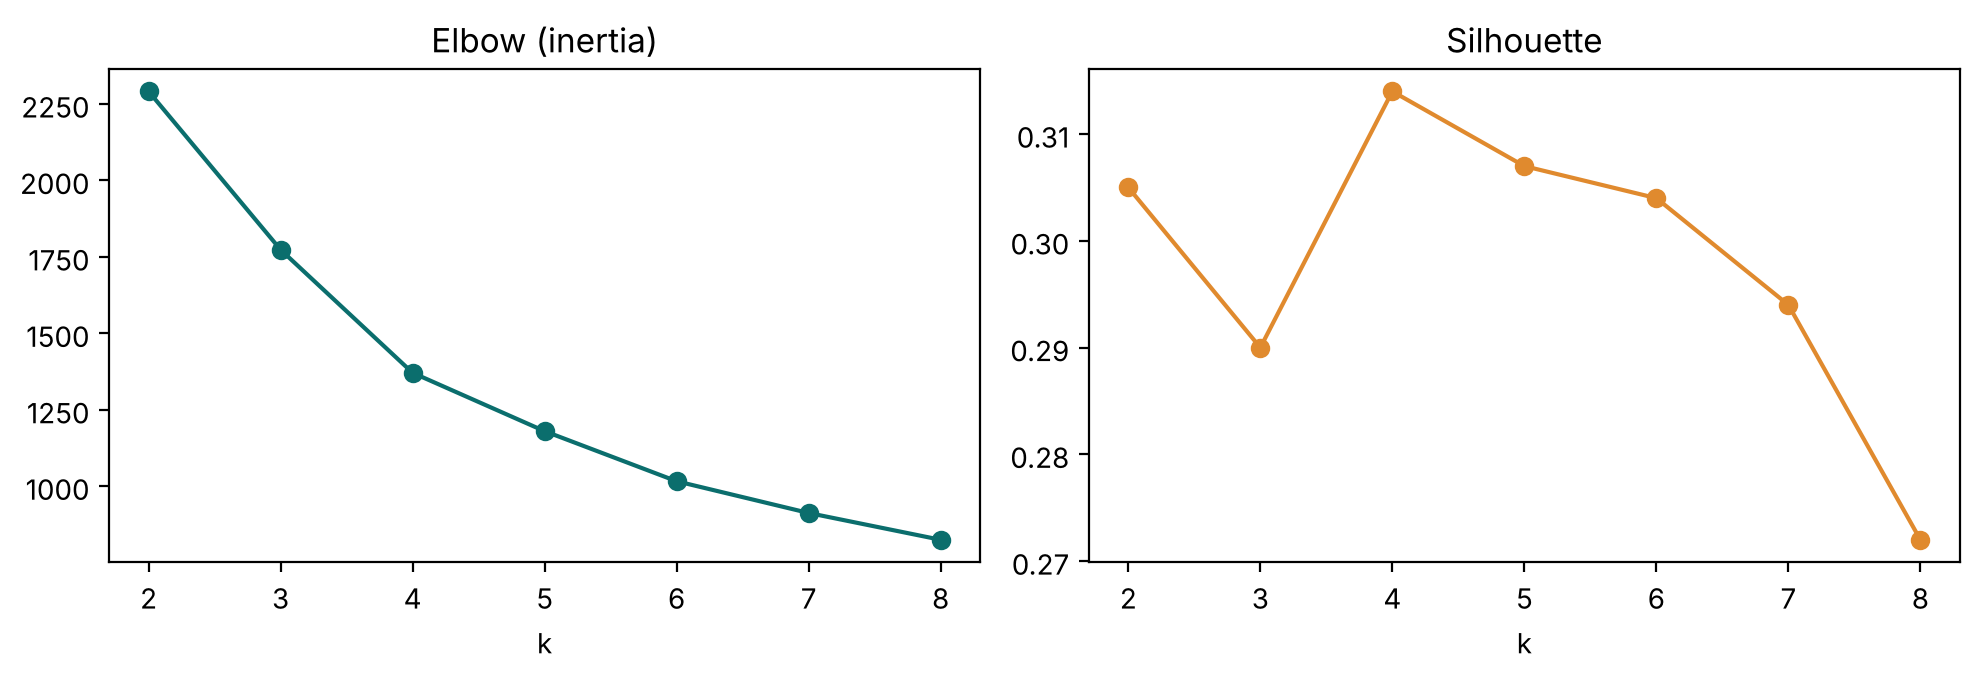

,inertia,silhouette
k,,
2,2291.424,0.305
3,1773.629,0.290
4,1370.992,0.314
5,1180.150,0.307
6,1016.372,0.304
7,912.575,0.294
8,824.882,0.272


In [27]:
from sklearn.metrics import silhouette_score

seg_X = StandardScaler().fit_transform(seg_raw)
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(seg_X)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(seg_X, km.labels_)})
k_table = pd.DataFrame(rows).set_index("k").round(3)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
k_table.inertia.plot(ax=ax[0], marker="o", title="Elbow (inertia)", color="#0B6E6D")
k_table.silhouette.plot(ax=ax[1], marker="o", title="Silhouette", color="#E08A2E")
plt.tight_layout(); plt.show()
k_table

**What to notice:** on real customer data the elbow is soft and silhouette scores are modest (well below the ~0.8 you see on toy
blobs). That's normal — customers vary continuously, they don't come in neat bubbles.

### 6.1 Caution 1: k-means always finds clusters — even in pure noise

In [28]:
rng = np.random.default_rng(SEED)
noise = rng.uniform(size=(500, 2))                         # no structure at all
for k in [2, 3, 4]:
    lab = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(noise)
    print(f"k={k}: silhouette on random noise = {silhouette_score(noise, lab):.3f}")

k=2: silhouette on random noise = 0.382
k=3: silhouette on random noise = 0.390
k=4: silhouette on random noise = 0.424


**What to notice:** uniform random noise gets a **higher** silhouette (≈0.4) than our real customer data (≈0.3).
A “decent” silhouette does **not** prove that real groups exist.

### 6.2 Caution 2: are the clusters stable across random starts?

In [29]:
from sklearn.metrics import adjusted_rand_score

def stability(X, k, seeds=range(5)):
    labels = [KMeans(n_clusters=k, n_init=1, random_state=s).fit_predict(X) for s in seeds]
    scores = [adjusted_rand_score(labels[0], l) for l in labels[1:]]
    return np.mean(scores)

for k in [2, 4, 7]:
    print(f"k={k}: mean agreement between runs (ARI, 1 = identical) = {stability(seg_X, k):.3f}")

k=2: mean agreement between runs (ARI, 1 = identical) = 0.185
k=4: mean agreement between runs (ARI, 1 = identical) = 0.683
k=7: mean agreement between runs (ARI, 1 = identical) = 0.467


**What to notice:** with a single random start (`n_init=1`) the labels often change from run to run — agreement is far below 1.
That's why we use `n_init=10` and treat segment boundaries as soft, not exact.

### 6.3 Caution 3: scaling choices change the clusters

In [30]:
lab_scaled = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit_predict(seg_X)
lab_raw    = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit_predict(seg_raw)
print("Agreement scaled vs unscaled (ARI):", round(adjusted_rand_score(lab_scaled, lab_raw), 3))
print("\nUnscaled clusters are driven by the biggest-number column:")
print(df.assign(raw_cluster=lab_raw).groupby("raw_cluster")[seg_cols].mean().round(1))

Agreement scaled vs unscaled (ARI): 0.29

Unscaled clusters are driven by the biggest-number column:
             tenure_months  monthly_charges  support_calls
raw_cluster                                               
0                     17.9             59.0            1.5
1                     24.8            116.2            1.5
2                     23.1            346.6            1.6
3                     53.1             69.2            1.6


### 6.4 Interpreting clusters responsibly
* Clusters are **descriptions of this data**, not natural laws or causes.
* A name like *“loyal low-spenders”* is a **label we chose** — check it against the averages and spread.
* Results depend on: which features, how they're scaled, *k*, and the random start.
* Validate with people who know the business, and re-check on new data.

> ✍️ **Exercise 5–6:** Add `age` to the segmentation features. Does the best *k* by silhouette change? Do the segment profiles still
> make business sense?

---
## 7. Hyperparameter tuning with `GridSearchCV` / `RandomizedSearchCV`

**Parameters** are learned from data (coefficients). **Hyperparameters** are set before training (`C`, `max_depth`, `n_estimators`).
Tuning tries settings with **cross-validation on the training set only** — the test set stays untouched until the very end.

* `GridSearchCV`: tries **every** combination → thorough, slow
* `RandomizedSearchCV`: tries **n_iter random** combinations from distributions → much faster for big spaces

Inside a pipeline, name parameters as `step__param`, e.g. `clf__C` or `prep__num__impute__strategy`.

In [31]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

grid = {
    "clf__C": [0.01, 0.1, 1, 10],
    "prep__num__impute__strategy": ["mean", "median"],
}
t0 = time.time()
gs = GridSearchCV(model, grid, cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
print(f"Grid search: {len(gs.cv_results_['params'])} combos × 5 folds in {time.time()-t0:.1f}s")
print("Best params:", gs.best_params_, "| best CV ROC-AUC:", round(gs.best_score_, 3))

(pd.DataFrame(gs.cv_results_)
   [["param_clf__C", "param_prep__num__impute__strategy", "mean_test_score", "std_test_score", "rank_test_score"]]
   .sort_values("rank_test_score").round(3).head())

Grid search: 8 combos × 5 folds in 2.1s
Best params: {'clf__C': 0.1, 'prep__num__impute__strategy': 'mean'} | best CV ROC-AUC: 0.832


,param_clf__C,param_prep__num__impute__strategy,mean_test_score,std_test_score,rank_test_score
3,0.10,median,0.832,0.032,1
2,0.10,mean,0.832,0.032,1
4,1.00,mean,0.831,0.031,3
5,1.00,median,0.831,0.031,4
0,0.01,mean,0.830,0.034,5


In [32]:
from scipy.stats import randint, uniform

rf_model = Pipeline(model.steps[:-1] + [("clf", RandomForestClassifier(random_state=SEED))])
space = {
    "clf__n_estimators": randint(100, 400),
    "clf__max_depth": [None, 4, 6, 8, 12],
    "clf__min_samples_leaf": randint(1, 20),
    "clf__max_features": uniform(0.2, 0.7),        # fraction of features per split, 0.2–0.9
}
t0 = time.time()
rs = RandomizedSearchCV(rf_model, space, n_iter=20, cv=cv, scoring="roc_auc",
                        random_state=SEED, n_jobs=-1).fit(X_train, y_train)
print(f"Random search: 20 combos × 5 folds in {time.time()-t0:.1f}s")
print("Best params:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in rs.best_params_.items()})
print("Best CV ROC-AUC:", round(rs.best_score_, 3))

Random search: 20 combos × 5 folds in 23.5s
Best params: {'clf__max_depth': 4, 'clf__max_features': np.float64(0.233), 'clf__min_samples_leaf': 16, 'clf__n_estimators': 370}
Best CV ROC-AUC: 0.812


In [33]:
from sklearn.metrics import roc_auc_score, classification_report

# Final, ONE-TIME check on the untouched test set
for name, search in [("Logistic regression (grid)", gs), ("Random forest (random)", rs)]:
    proba = search.best_estimator_.predict_proba(X_test)[:, 1]
    print(f"{name:28s} CV AUC = {search.best_score_:.3f} | test AUC = {roc_auc_score(y_test, proba):.3f}")

print("\n", classification_report(y_test, gs.best_estimator_.predict(X_test), digits=3))

Logistic regression (grid)   CV AUC = 0.832 | test AUC = 0.788
Random forest (random)       CV AUC = 0.812 | test AUC = 0.788

               precision    recall  f1-score   support

           0      0.700     0.737     0.718        95
           1      0.750     0.714     0.732       105

    accuracy                          0.725       200
   macro avg      0.725     0.726     0.725       200
weighted avg      0.726     0.725     0.725       200



**What to notice:** the simpler logistic regression matches the tuned forest on the test set (both ≈0.79 AUC) — the hidden churn
rule we generated is logistic, so that's expected. Test AUC is a little below CV AUC: the best CV score is slightly optimistic
because we *picked* it among many tries. Tuning gives small gains; good features and clean preprocessing usually matter more.

> ✍️ **Exercise 7:** Run `RandomizedSearchCV` with `n_iter=5` and `n_iter=50`. Plot best score vs time. When is a grid search still worth it?

---
## 8. Cross-validation and reproducibility

A single train/test split is one noisy measurement. **k-fold cross-validation** trains *k* models, each tested on a different fold,
and reports the mean ± spread.

* `KFold` — plain folds; `StratifiedKFold` — keeps the class balance in every fold (use for classification)
* `cross_val_score` — one metric; `cross_validate` — several metrics + timings
* Time series → `TimeSeriesSplit` (never train on the future); grouped data → `GroupKFold`

In [34]:
from sklearn.model_selection import cross_val_score, cross_validate, KFold

scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
print("Fold ROC-AUCs:", scores.round(3))
print(f"Mean ± std   : {scores.mean():.3f} ± {scores.std():.3f}")

res = cross_validate(model, X_train, y_train, cv=cv,
                     scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
pd.DataFrame(res).drop(columns=["fit_time", "score_time"]).agg(["mean", "std"]).round(3)

Fold ROC-AUCs: [0.872 0.797 0.86  0.829 0.799]
Mean ± std   : 0.831 ± 0.031


,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.746,0.742,0.790,0.765,0.831
std,0.035,0.031,0.058,0.036,0.034


### 8.1 Data leakage: why preprocessing must live *inside* the pipeline
Classic demonstration: 100 rows of **pure random noise** with random labels. No model can really beat 50%.
If we select the “best” features on **all** the data *before* cross-validation, CV looks impressive — a lie.

In [35]:
rng = np.random.default_rng(SEED)
X_noise = rng.normal(size=(100, 5000))
y_noise = rng.integers(0, 2, 100)
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)

# WRONG: select features using all labels, then cross-validate
X_leaky = SelectKBest(k=20).fit_transform(X_noise, y_noise)
wrong = cross_val_score(LogisticRegression(max_iter=1000), X_leaky, y_noise, cv=cv5).mean()

# RIGHT: selection inside the pipeline → refit on each training fold only
right_pipe = make_pipeline(SelectKBest(k=20), LogisticRegression(max_iter=1000))
right = cross_val_score(right_pipe, X_noise, y_noise, cv=cv5).mean()

print(f"Leaky CV accuracy on pure noise : {wrong:.3f}   ← looks great, is fake")
print(f"Honest CV accuracy on pure noise: {right:.3f}   ← about a coin flip, the truth")

Leaky CV accuracy on pure noise : 0.880   ← looks great, is fake
Honest CV accuracy on pure noise: 0.530   ← about a coin flip, the truth


### 8.2 Reproducibility checklist
1. Fix `random_state` in **every** random step: split, CV shuffling, models, searches, k-means.
2. Keep preprocessing in a `Pipeline` so it's re-run identically.
3. Record library versions (results can change between versions).
4. Save the data version / hash and the exact parameters with the model (Section 10).
5. Run *Restart & Run All* before sharing — hidden state in a notebook is a classic source of “it worked on my machine”.

In [36]:
def run_once(seed):
    Xa, Xb_, ya, yb = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
    m = Pipeline(model.steps[:-1] + [("clf", RandomForestClassifier(n_estimators=100, random_state=seed))])
    return round(m.fit(Xa, ya).score(Xb_, yb), 4)

print("Same seed twice   :", run_once(SEED), run_once(SEED), " ← identical")
print("Different seeds   :", [run_once(s) for s in [1, 2, 3]], " ← the split alone moves the score")

Same seed twice   : 0.715 0.715  ← identical


Different seeds   : [0.725, 0.715, 0.76]  ← the split alone moves the score


**What to notice:** with the same seed, results are bit-for-bit identical. Changing only the seed moves accuracy by a few points —
which is exactly why we report CV **mean ± std** rather than one lucky split.

> ✍️ **Exercise 8:** Compare `KFold(5, shuffle=False)` with `StratifiedKFold(5, shuffle=True, random_state=SEED)`. Print the churn rate in each test fold.

---
## 9. Feature importance and interpretability caveats

| Method | What it measures | Main caveat |
|---|---|---|
| Linear coefficients (scaled features) | direction and size of effect, holding others fixed | unstable with correlated features; scale-dependent |
| Tree **impurity** importance (`feature_importances_`) | how much splits on a feature reduce impurity, on **training** data | **biased toward high-cardinality / continuous features**, even random ones |
| **Permutation importance** | how much the test score drops when a feature is shuffled | correlated features share (and hide) importance; slower |

And for all of them: **importance ≠ causation.**

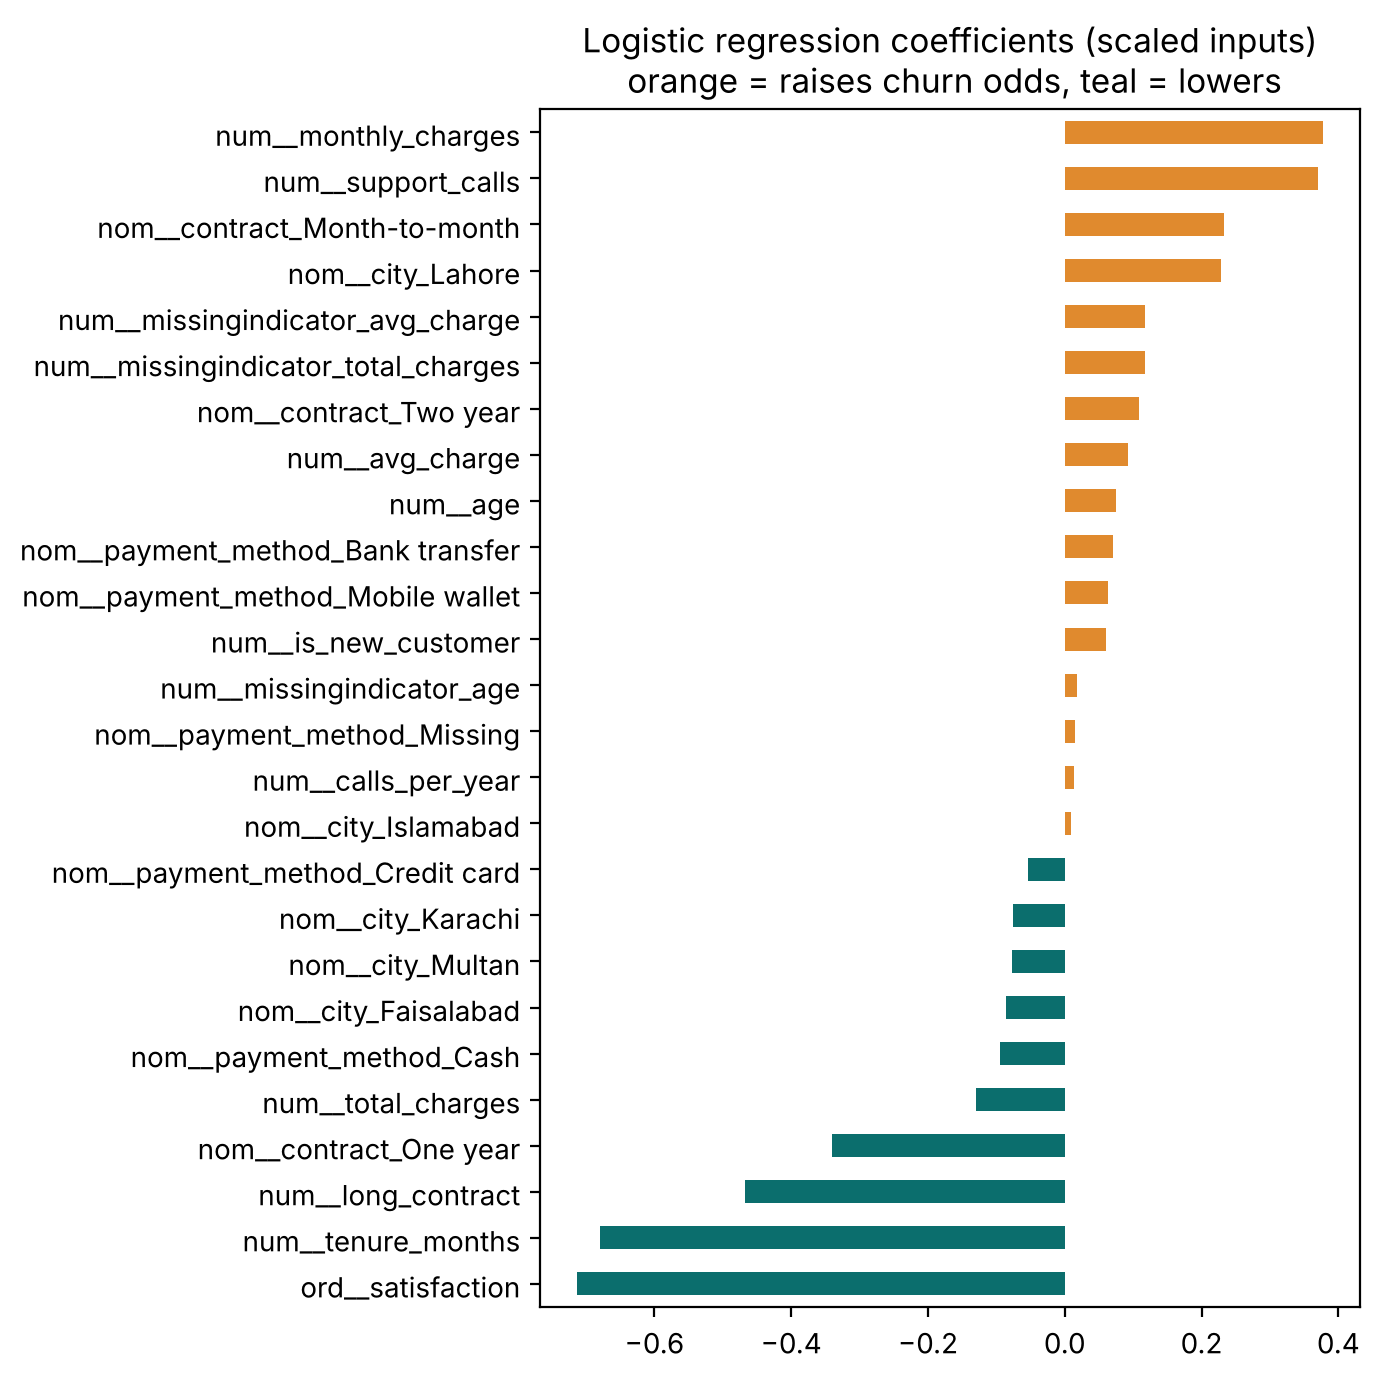

In [37]:
best_lr = gs.best_estimator_
coef = pd.Series(best_lr.named_steps["clf"].coef_[0],
                 index=best_lr.named_steps["prep"].get_feature_names_out())
coef.sort_values().plot.barh(figsize=(7, 7), color=np.where(coef.sort_values() > 0, "#E08A2E", "#0B6E6D"))
plt.title("Logistic regression coefficients (scaled inputs)\n orange = raises churn odds, teal = lowers")
plt.tight_layout(); plt.show()

### 9.1 The impurity-importance trap: a random ID-like column looks important

In [38]:
from sklearn.inspection import permutation_importance

rng = np.random.default_rng(SEED)
X_tr_r = X_train.assign(random_id=rng.random(len(X_train)))   # pure noise, but continuous & unique
X_te_r = X_test.assign(random_id=rng.random(len(X_test)))

prep_r = ColumnTransformer([("num", num_pipe, numeric + ["random_id"]),
                            ("nom", nom_pipe, nominal), ("ord", ord_pipe, ordinal)])
rf_r = Pipeline([("features", FunctionTransformer(add_domain_features)),
                 ("prep", prep_r),
                 ("clf", RandomForestClassifier(n_estimators=300, random_state=SEED))]).fit(X_tr_r, y_train)

impurity = pd.Series(rf_r.named_steps["clf"].feature_importances_,
                     index=rf_r.named_steps["prep"].get_feature_names_out())

perm = permutation_importance(rf_r, X_te_r, y_test, n_repeats=10, random_state=SEED, scoring="roc_auc")
perm_s = pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std}, index=X_te_r.columns)

print("Impurity importance (train) — top 6:")
print(impurity.sort_values(ascending=False).head(6).round(3))
print("\nPermutation importance (test ROC-AUC drop) — all raw columns:")
print(perm_s.sort_values("mean", ascending=False).round(4))

Impurity importance (train) — top 6:
num__tenure_months      0.134
num__calls_per_year     0.093
num__total_charges      0.087
num__monthly_charges    0.086
num__avg_charge         0.084
num__random_id          0.082
dtype: float64

Permutation importance (test ROC-AUC drop) — all raw columns:
                   mean     std
contract         0.1101  0.0344
tenure_months    0.0765  0.0364
support_calls    0.0287  0.0087
satisfaction     0.0124  0.0076
random_id        0.0084  0.0039
monthly_charges  0.0049  0.0055
total_charges    0.0010  0.0089
payment_method   0.0001  0.0047
city            -0.0001  0.0057
age             -0.0067  0.0069


**What to notice:** the meaningless `random_id` lands in the **impurity** top 6 — almost as “important” as monthly charges —
because trees can split on any unique-ish number to memorise training rows. On the test set its **permutation** importance is
tiny (≈0.008 vs ≈0.11 for `contract`) — yet not exactly zero: with only 200 test rows, pure noise can look slightly useful.
That's why you compare against the spread, repeat with other seeds, and are suspicious of small values. A **negative** value (here `age`) means shuffling the column
did not hurt at all. Permutation importance on held-out data is the safer default — and always read it with its spread.

### 9.2 Caveats to always state
1. **Correlated features split credit.** `tenure_months`, `total_charges` and `long_contract` carry overlapping information; removing
   one can make another look more important.
2. **Importance describes the model, not the world.** A bad model's importances describe a bad model.
3. **Not causal.** “Support calls drive churn” might really be “unhappy customers both call more and leave”.
4. **Depends on the data split and seed** — check stability (repeat with other seeds).
5. Global importance hides **individual** explanations; tools like SHAP or partial dependence plots help, with their own caveats.

> ✍️ **Exercise 9:** Drop `total_charges` and recompute permutation importance. What happens to `tenure_months` and `long_contract`?

---
## 10. Model persistence with `joblib`

Save the **whole fitted pipeline** (preprocessing + model), not only the model — otherwise you must re-create the exact same
preprocessing at prediction time.

Also save **metadata**: library versions, training date, features, parameters, CV and test metrics, data hash.

In [39]:
import joblib, hashlib, platform
from pathlib import Path
from datetime import datetime, timezone

final_model = gs.best_estimator_                  # already refit on the full training set
out = Path("models"); out.mkdir(exist_ok=True)
model_path = out / "churn_pipeline_v1.joblib"
joblib.dump(final_model, model_path, compress=3)

meta = {
    "model_file": model_path.name,
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "python": platform.python_version(),
    "sklearn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__,
    "input_columns": list(X_train.columns),
    "best_params": {k: (v if not isinstance(v, np.generic) else v.item()) for k, v in gs.best_params_.items()},
    "cv_roc_auc": round(gs.best_score_, 4),
    "test_roc_auc": round(roc_auc_score(y_test, final_model.predict_proba(X_test)[:, 1]), 4),
    "train_data_sha256": hashlib.sha256(pd.util.hash_pandas_object(X_train, index=True).values.tobytes()).hexdigest()[:16],
    "random_state": SEED,
}
(out / "churn_pipeline_v1.json").write_text(json.dumps(meta, indent=2))
print(f"Saved {model_path} ({model_path.stat().st_size/1024:.1f} KB)")
print(json.dumps(meta, indent=2))

Saved models/churn_pipeline_v1.joblib (2.9 KB)
{
  "model_file": "churn_pipeline_v1.joblib",
  "created_utc": "2026-11-25T15:21:18+00:00",
  "python": "3.13.18",
  "sklearn": "1.9.1",
  "pandas": "3.0.5",
  "numpy": "2.5.3",
  "input_columns": [
    "age",
    "city",
    "contract",
    "payment_method",
    "tenure_months",
    "monthly_charges",
    "total_charges",
    "support_calls",
    "satisfaction"
  ],
  "best_params": {
    "clf__C": 0.1,
    "prep__num__impute__strategy": "mean"
  },
  "cv_roc_auc": 0.8323,
  "test_roc_auc": 0.7878,
  "train_data_sha256": "f4ab9703dbb160bb",
  "random_state": 42
}


In [40]:
# Later — e.g. in an API or a nightly batch job — load and predict on RAW data
loaded = joblib.load(model_path)
same = np.allclose(loaded.predict_proba(X_test), final_model.predict_proba(X_test))
print("Loaded model gives identical predictions:", same)

loaded_meta = json.loads((out / "churn_pipeline_v1.json").read_text())
missing_cols = set(loaded_meta["input_columns"]) - set(new_customers.columns)
assert not missing_cols, f"Input is missing columns: {missing_cols}"
new_customers.assign(churn_probability=loaded.predict_proba(new_customers)[:, 1].round(3))

Loaded model gives identical predictions: True


,age,city,contract,payment_method,tenure_months,monthly_charges,total_charges,support_calls,satisfaction,churn_probability
0,NaN,Quetta,Month-to-month,NaN,2,95.0,NaN,4,Low,0.993
1,45.0,Lahore,Two year,Bank transfer,60,55.0,3300.0,0,High,0.055


### 10.1 Persistence rules
* ✅ Load with the **same scikit-learn version** that saved it (check `meta["sklearn"]`); pin versions in `requirements.txt`.
* ✅ Version your files (`_v1`, `_v2`) and keep the metadata JSON beside each one.
* ✅ Validate input columns before predicting.
* ⚠️ **Security:** `joblib.load` runs pickle — **never load a model file from an untrusted source**; it can execute code.
* ⚠️ The custom function `add_domain_features` must be importable when loading. In production, put it in a module (e.g. `features.py`)
  rather than defining it in a notebook.

> ✍️ **Exercise 10:** Save the random forest from Section 7 as `churn_pipeline_v2.joblib` with its own metadata. Write a function
> `predict_file(csv_path, model_path)` that loads both and writes predictions to a CSV.

---
## Summary

| Topic | Key takeaway |
|---|---|
| Missing values | Ask *why* it's missing; median for skew; add indicators when missingness is informative |
| Encoding | One-hot for nominal, ordinal with explicit order; `handle_unknown="ignore"` |
| Scaling | Needed for distance/gradient models, not trees; `RobustScaler` for outliers |
| Features | Domain knowledge first; selection methods are evidence, not truth |
| Pipelines | `ColumnTransformer` + `Pipeline` = no leakage, one object from raw data to prediction |
| K-means | Scale first; profile segments with original units |
| Choosing *k* | Elbow + silhouette + stability + usefulness; k-means finds clusters even in noise |
| Tuning | Search on training folds only; test set once at the end |
| Cross-validation | Mean ± std; all preprocessing inside the CV loop; fix seeds |
| Importance | Prefer permutation importance on test data; correlated ≠ unimportant; not causal |
| Persistence | Save the whole pipeline + metadata; same versions; never load untrusted files |